In [3]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['achleitner-Aus_Kroatien.txt', 'achleitner-Bergrichters_Erdenwallen.txt', 'achleitner-Celsissimus.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 01.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 66.txt', 'goethe-die_leiden_des_jungen_werther_band1.txt', 'goethe-die_leiden_des_jungen_werther_band2.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'goethe-wahlverwandtschaften.txt', 'goethe-wilhelm_meisters_lehrjahre_band1.txt', 'goethe-wilhelm_meisters_wanderjahre_band1.txt', 'kafka-betrachtung.txt', 'kafka-das_urteil.txt', 'kafka-der_prozess.txt', 'kafka-die_verwandlung.txt', 'kafka-hungerküns

In [4]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\textstat\textstat.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [5]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

33281 1853
5.8 18.0 1.9 0.63 0.22
Anzahl eindeutiger Bigramme: 28450
Anzahl eindeutiger Trigramme: 38070

Top 5 Bigramme:
(',', 'daß') → 218 Mal
('!', '“') → 199 Mal
(',', 'die') → 150 Mal
(',', 'der') → 125 Mal
('.', 'der') → 121 Mal

Top 5 Trigramme:
('!', '“', '„') → 65 Mal
(',', 'daß', 'der') → 46 Mal
('?', '“', '„') → 32 Mal
(',', 'daß', 'die') → 26 Mal
(',', 'daß', 'er') → 13 Mal
None
-----------------------------------------------
46250 2530
5.5 18.3 1.8 0.56 0.17
Anzahl eindeutiger Bigramme: 35653
Anzahl eindeutiger Trigramme: 50585

Top 5 Bigramme:
('!', '“') → 592 Mal
('“', '„') → 586 Mal
('.', '„') → 301 Mal
('?', '“') → 285 Mal
(',', 'daß') → 259 Mal

Top 5 Trigramme:
('!', '“', '„') → 309 Mal
('?', '“', '„') → 207 Mal
('“', '„', 'ich') → 44 Mal
(',', 'daß', 'der') → 38 Mal
('“', '„', 'ja') → 35 Mal
None
-----------------------------------------------
68271 2948
5.5 23.2 1.8 1.43 0.16
Anzahl eindeutiger Bigramme: 50872
Anzahl eindeutiger Trigramme: 73676

Top 5 Bigramme:
('

# Decision Tree

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import KFold, cross_val_score
import sklearn.metrics as metrics
import pandas as pd
import matplotlib.pyplot as plt

colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp["Author"]= ["Achleitner", "Achleitner", "Achleitner", "Achleitner", "Achleitner", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller"]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003,Achleitner
1,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002,Achleitner
2,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004,Achleitner
3,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,Achleitner
4,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,Achleitner
5,5.4,18.9,1.8,0.69,104.4,0.21,0.004,0.002,0.042,0.088,0.000,0.000,Anonymous
6,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,Anonymous
7,5.4,16.6,1.8,0.32,106.7,0.20,0.001,0.002,0.049,0.074,0.000,0.000,Anonymous
8,5.4,16.6,1.8,0.32,106.7,0.21,0.001,0.001,0.051,0.072,0.000,0.000,Anonymous
9,5.5,15.3,1.8,0.10,108.0,0.21,0.001,0.001,0.054,0.073,0.000,0.000,Anonymous


In [ ]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [ ]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2) # 80% training and 20% test

# Create Decision Tree classifer object
clf = tree.DecisionTreeClassifier()

# Train Decision Tree Classifer
clf_fit = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf_fit.predict(X_test)

#X = corp.iloc[:,0:12]
#y = corp.iloc[:,12]

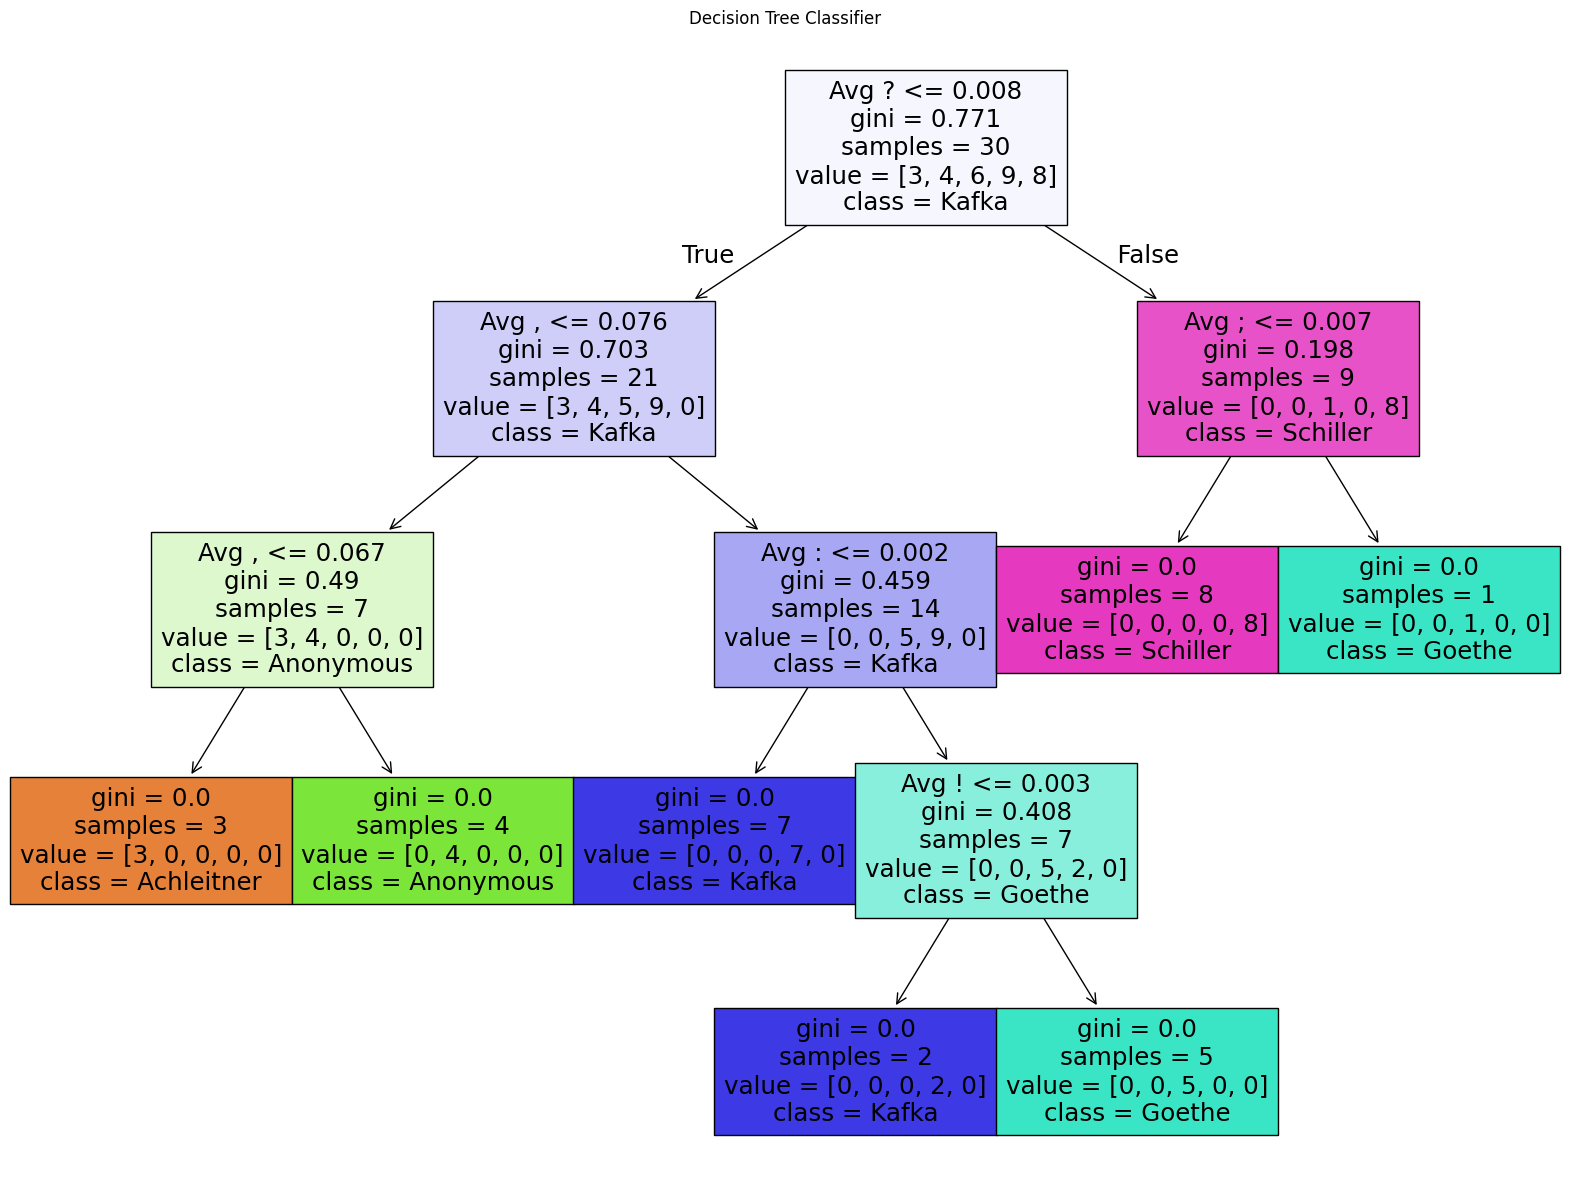

In [8]:
plt.figure(figsize=(20, 15))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Achleitner', 'Anonymous', 'Goethe', 'Kafka', 'Schiller'])
plt.title("Decision Tree Classifier")
plt.show()

In [9]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.75


In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      0.50      0.67         2
   Anonymous       0.50      0.50      0.50         2
      Goethe       1.00      1.00      1.00         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      1.00      1.00         2

    accuracy                           0.75         8
   macro avg       0.80      0.80      0.77         8
weighted avg       0.81      0.75      0.75         8



In [11]:
y_test

24         Kafka
32      Schiller
2     Achleitner
12        Goethe
7      Anonymous
5      Anonymous
33      Schiller
3     Achleitner
Name: Author, dtype: object

In [12]:
y_pred

array(['Kafka', 'Schiller', 'Anonymous', 'Goethe', 'Anonymous', 'Kafka',
       'Schiller', 'Achleitner'], dtype=object)

In [13]:
confusion_matrix(y_test, y_pred)

array([[1, 1, 0, 0, 0],
       [0, 1, 0, 1, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 2]])

In [22]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
24,Kafka,Kafka
32,Schiller,Schiller
2,Achleitner,Anonymous
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
33,Schiller,Schiller
3,Achleitner,Achleitner


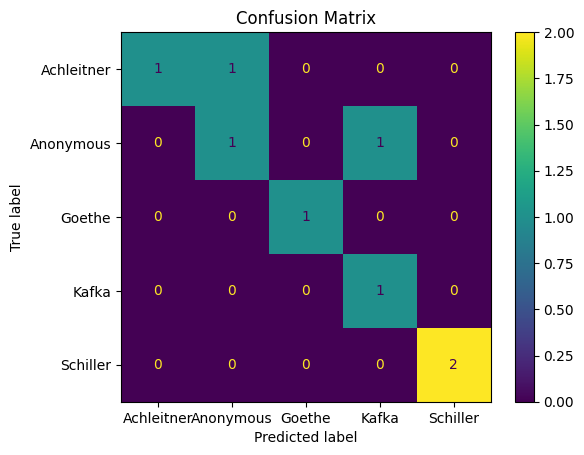

In [ ]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Achleitner', 'Anonymous',  'Goethe', 'Kafka', 'Schiller']) #Alphabetiche Reihenfolge?

cm_display.plot()
plt.title("Confusion Matrix")
plt.show()

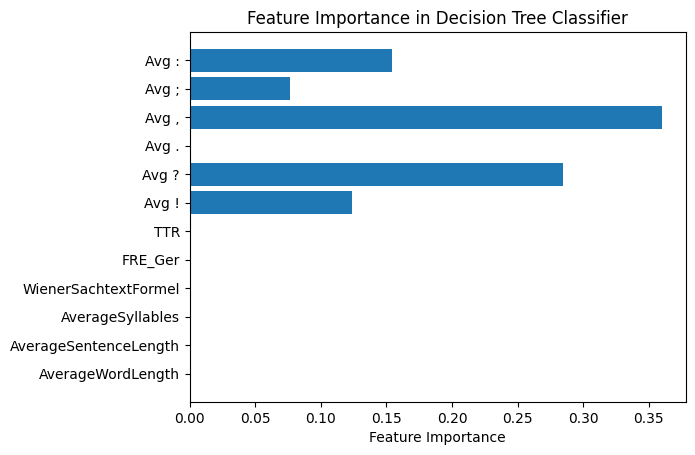

In [19]:
feature_importances = clf_fit.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Decision Tree Classifier')
plt.show()

In [16]:
features = pd.DataFrame(clf_fit.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.000000
AverageSentenceLength,0.000000
AverageSyllables,0.000000
WienerSachtextFormel,0.000000
FRE_Ger,0.000000
TTR,0.000000
Avg !,0.123508
Avg ?,0.285028
Avg .,0.000000
"Avg ,",0.360231
